# Practica 2 Normalización y Estandarización


![ITQ logo](Imagenes/ITQ.png)

**Nombre** Jose Silva

**Fecha** 9/11/2026

**Link** <a href="https://github.com/josesil27/Machine-Learning-"> Link Repositorio </a>

**Objetivos**

Aplicar las fases de comprensión del negocio y comprensión de los datos de CRISP-DM, y desarrollar la preparación de datos hasta la normalización Min-Max y la estandarización Z-score, mediante el análisis reproducible de más de 100 000 registros de hospitalizaciones de pacientes con diabetes en Python. 

**Antecedentes y escenario**

El conjunto Diabetes 130-US Hospital for Years 1999–2008, publicado en UCI, contiene 101 766 hospitalizaciones registradas en 130 hospitales y redes de atención de Estados Unidos. Una fila representa una hospitalización, no necesariamente un paciente diferente. Incluye variables demográficas, de atención y de readmisión hospitalaria. 

En esta actividad, un equipo de análisis debe comprender la información y preparar variables numéricas con distintas escalas. El análisis es académico y no permite emitir diagnósticos ni establecer relaciones causales. 

In [1]:
#Instalar la libreria
%pip install -q ucimlrepo 

Note: you may need to restart the kernel to use updated packages.


In [2]:
#Importacion de librerias
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn import preprocessing

Describa el problema de las readmisiones hospitalarias, los actores interesados y la utilidad de explorar los datos antes de modelar. 

El problema de la readmision de pacientes podrian involucrar una mala tencion en el paciente, costos para el hospital, los actores interesados son; el hospital, los pacientes y los doctores, la utilidad de explorar estos datos antes de modelar es conocer las razones por las cuales se hacen las readmisiones y borrar los datos del data set que no sean relevantes para el modelado.} 

• Formule un objetivo general, al menos dos preguntas de análisis y criterios verificables de éxito para esta práctica. 

El objetivo es conocer el por qué los pacientes son readmitidos. 

¿Los pacientes son readmitidos por una mala atención medica? 

¿Qué factores influyen para la readmisión del paciente? 

• Identifique readmitted como variable de referencia y consulte el significado de NO, <30 y >30 en la documentación. No la escale. 

El NO <30 y >30 son un periodo de tiempo del que paciente vuelve después del alta menor a 30 quiere decir que fue en menos de un mes y mayor a 30 es que es después de un mes del alta y el NO quiere decir que el paciente no volvio después del alta médica. 

• Explique los límites del periodo 1999–2008, la población hospitalaria y la presencia de varias hospitalizaciones del mismo paciente. Considere la confidencialidad y evite intentar identificar personas. 

Los límites del periodo dado es que son datos viejos ya que han pasado más de 10 años de cuando se retomó los datos además son datos de hospitales de EE. UU. por lo tanto puede variar de país a país. 

In [3]:

from ucimlrepo import fetch_ucirepo 

# Descargar el conjunto de datos desde UCI. 
dataset = fetch_ucirepo(id=296) 

# Obtener una copia de todos los datos. 
df = dataset.data.original.copy() 

# Verificar que cumple con el tamaño solicitado. 
print("Filas y columnas:", df.shape) 
assert len(df) > 100_000, "El dataset debe superar los 100 000 registros." 

# Visualizar los primeros registros. 
display(df.head()) 

# Consultar el diccionario de variables. 
display(dataset.variables) 

# Guardar una copia local para desarrollar la actividad. 
df.to_csv("hospitalizaciones_diabetes_original.csv", index=False) 

Filas y columnas: (101766, 50)


C:\Users\ign-n\anaconda3\envs\practicasmachinelearning\Lib\site-packages\ucimlrepo\fetch.py:97: DtypeWarning: Columns (10: payer_code) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_url)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


,name,role,type,demographic,description,units,missing_values
0,encounter_id,ID,,NaN,Unique identifier of an encounter,None,no
1,patient_nbr,ID,,NaN,Unique identifier of a patient,None,no
2,race,Feature,Categorical,Race,"Values: Caucasian, Asian, African American, Hi...",None,yes
3,gender,Feature,Categorical,Gender,"Values: male, female, and unknown/invalid",None,no
4,age,Feature,Categorical,Age,"Grouped in 10-year intervals: [0, 10), [10, 20...",None,no
5,weight,Feature,Categorical,NaN,Weight in pounds.,None,yes
6,admission_type_id,Feature,Categorical,NaN,Integer identifier corresponding to 9 distinct...,None,no
7,discharge_disposition_id,Feature,Categorical,NaN,Integer identifier corresponding to 29 distinc...,None,no
8,admission_source_id,Feature,Categorical,NaN,Integer identifier corresponding to 21 distinc...,None,no
9,time_in_hospital,Feature,Integer,NaN,Integer number of days between admission and d...,None,no


In [4]:
#Verificar si los datos del dataset
df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [5]:
#construccion  del diccionario\

#crear la variable diccionario con las columnas y los tipos de datos que tienen
diccionario= pd.DataFrame({"columna":df.columns,
                           "tipo_de_dato": df.dtypes.astype(str).values,
                          })

#Escribir el significado de cada columna
significado = {
    "encounter_id": "Identificador único de la hospitalización (encuentro)",
    "patient_nbr": "Identificador único del paciente",
    "race": "Raza del paciente",
    "gender": "Género del paciente",
    "age": "Edad del paciente agrupada en intervalos de 10 años",
    "weight": "Peso del paciente en libras",
    "admission_type_id": "Código del tipo de admisión (emergencia, urgencia, electiva, etc.)",
    "discharge_disposition_id": "Código del destino del paciente al alta (domicilio, traslado, fallecimiento, etc.)",
    "admission_source_id": "Código de la procedencia del ingreso (derivación médica, sala de emergencias, etc.)",
    "time_in_hospital": "Duración de la hospitalización en días",
    "payer_code": "Código del pagador o seguro del paciente",
    "medical_specialty": "Especialidad del médico que admitió al paciente",
    "num_lab_procedures": "Número de pruebas de laboratorio realizadas durante la hospitalización",
    "num_procedures": "Número de procedimientos (distintos de laboratorio) realizados durante la hospitalización",
    "num_medications": "Número de medicamentos distintos administrados durante la hospitalización",
    "number_outpatient": "Número de visitas ambulatorias del paciente en el año previo",
    "number_emergency": "Número de visitas de emergencia del paciente en el año previo",
    "number_inpatient": "Número de hospitalizaciones del paciente en el año previo",
    "diag_1": "Diagnóstico principal (código ICD-9)",
    "diag_2": "Diagnóstico secundario (código ICD-9)",
    "diag_3": "Diagnóstico secundario adicional (código ICD-9)",
    "number_diagnoses": "Número total de diagnósticos registrados en el sistema",
    "max_glu_serum": "Resultado de la prueba de glucosa sérica (>200, >300, Norm, None si no se midió)",
    "A1Cresult": "Resultado de la prueba de hemoglobina glicosilada A1c (>8, >7, Norm, None si no se midió)",
    "metformin": "Indica si se prescribió metformina y si la dosis cambió (No, Steady, Up, Down)",
    "repaglinide": "Indica si se prescribió repaglinida y si la dosis cambió (No, Steady, Up, Down)",
    "nateglinide": "Indica si se prescribió nateglinida y si la dosis cambió (No, Steady, Up, Down)",
    "chlorpropamide": "Indica si se prescribió clorpropamida y si la dosis cambió (No, Steady, Up, Down)",
    "glimepiride": "Indica si se prescribió glimepirida y si la dosis cambió (No, Steady, Up, Down)",
    "acetohexamide": "Indica si se prescribió acetohexamida y si la dosis cambió (No, Steady, Up, Down)",
    "glipizide": "Indica si se prescribió glipizida y si la dosis cambió (No, Steady, Up, Down)",
    "glyburide": "Indica si se prescribió gliburida y si la dosis cambió (No, Steady, Up, Down)",
    "tolbutamide": "Indica si se prescribió tolbutamida y si la dosis cambió (No, Steady, Up, Down)",
    "pioglitazone": "Indica si se prescribió pioglitazona y si la dosis cambió (No, Steady, Up, Down)",
    "rosiglitazone": "Indica si se prescribió rosiglitazona y si la dosis cambió (No, Steady, Up, Down)",
    "acarbose": "Indica si se prescribió acarbosa y si la dosis cambió (No, Steady, Up, Down)",
    "miglitol": "Indica si se prescribió miglitol y si la dosis cambió (No, Steady, Up, Down)",
    "troglitazone": "Indica si se prescribió troglitazona y si la dosis cambió (No, Steady, Up, Down)",
    "tolazamide": "Indica si se prescribió tolazamida y si la dosis cambió (No, Steady, Up, Down)",
    "examide": "Indica si se prescribió examida y si la dosis cambió (No, Steady, Up, Down)",
    "citoglipton": "Indica si se prescribió citoglipton y si la dosis cambió (No, Steady, Up, Down)",
    "insulin": "Indica si se prescribió insulina y si la dosis cambió (No, Steady, Up, Down)",
    "glyburide-metformin": "Indica si se prescribió la combinación gliburida-metformina y si la dosis cambió",
    "glipizide-metformin": "Indica si se prescribió la combinación glipizida-metformina y si la dosis cambió",
    "glimepiride-pioglitazone": "Indica si se prescribió la combinación glimepirida-pioglitazona y si la dosis cambió",
    "metformin-rosiglitazone": "Indica si se prescribió la combinación metformina-rosiglitazona y si la dosis cambió",
    "metformin-pioglitazone": "Indica si se prescribió la combinación metformina-pioglitazona y si la dosis cambió",
    "change": "Indica si hubo cambio en los medicamentos para la diabetes (Ch = cambio, No = sin cambio)",
    "diabetesMed": "Indica si se prescribió algún medicamento para la diabetes (Yes / No)",
    "readmitted": "Readmisión del paciente: NO (sin reingreso), <30 (reingreso en menos de 30 días), >30 (reingreso después de 30 días)",}

#crear la tabla diccionario 
diccionario["significado"] = diccionario["columna"].map(significado)

#mostrar la tabla
display (diccionario)

,columna,tipo_de_dato,significado
0,encounter_id,int64,Identificador único de la hospitalización (enc...
1,patient_nbr,int64,Identificador único del paciente
2,race,str,Raza del paciente
3,gender,str,Género del paciente
4,age,str,Edad del paciente agrupada en intervalos de 10...
5,weight,str,Peso del paciente en libras
6,admission_type_id,int64,"Código del tipo de admisión (emergencia, urgen..."
7,discharge_disposition_id,int64,Código del destino del paciente al alta (domic...
8,admission_source_id,int64,Código de la procedencia del ingreso (derivaci...
9,time_in_hospital,int64,Duración de la hospitalización en días


In [6]:
#Verificamos si tenemos datos nulos si lo tenemos lo sumamos
df.isnull().sum()

encounter_id                    0
patient_nbr                     0
race                         2273
gender                          0
age                             0
weight                      98569
admission_type_id               0
discharge_disposition_id        0
admission_source_id             0
time_in_hospital                0
payer_code                  40256
medical_specialty           49949
num_lab_procedures              0
num_procedures                  0
num_medications                 0
number_outpatient               0
number_emergency                0
number_inpatient                0
diag_1                         21
diag_2                        358
diag_3                       1423
number_diagnoses                0
max_glu_serum               96420
A1Cresult                   84748
metformin                       0
repaglinide                     0
nateglinide                     0
chlorpropamide                  0
glimepiride                     0
acetohexamide 

In [7]:
#Duplicados de filas completas
dup_filas = df.duplicated().sum()
print("Filas completamente duplicadas:", dup_filas)
print(f"Porcentaje: {dup_filas / len(df) * 100:.2f}%")

Filas completamente duplicadas: 0
Porcentaje: 0.00%


In [8]:
#Duplicados en encounter_id (debe ser único: una fila = una hospitalización)
dup_encuentros = df["encounter_id"].duplicated().sum()
print("encounter_id repetidos:", dup_encuentros)
print("encounter_id únicos:", df["encounter_id"].nunique(), "de", len(df))

encounter_id repetidos: 0
encounter_id únicos: 101766 de 101766


In [9]:
#generar una variable con los datos cualitativos
cualitativas = [
    "race", "gender", "age", "weight",
    "payer_code", "medical_specialty",
    "admission_type_id", "discharge_disposition_id", "admission_source_id",
    "diag_1", "diag_2", "diag_3",
    "max_glu_serum", "A1Cresult",
    "metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride",
    "acetohexamide", "glipizide", "glyburide", "tolbutamide", "pioglitazone",
    "rosiglitazone", "acarbose", "miglitol", "troglitazone", "tolazamide",
    "examide", "citoglipton", "insulin", "glyburide-metformin",
    "glipizide-metformin", "glimepiride-pioglitazone",
    "metformin-rosiglitazone", "metformin-pioglitazone",
    "change", "diabetesMed",
]

#borrar los datos cualitativos
df_limpio = df.drop(columns=cualitativas)

df_limpio.head()

,encounter_id,patient_nbr,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,readmitted
0,2278392,8222157,1,41,0,1,0,0,0,1,NO
1,149190,55629189,3,59,0,18,0,0,0,9,>30
2,64410,86047875,2,11,5,13,2,0,1,6,NO
3,500364,82442376,2,44,1,16,0,0,0,7,NO
4,16680,42519267,1,51,0,8,0,0,0,5,NO


In [10]:
#Separamos los datos de entrada con nuestra variable objetivo
X=df_limpio.drop(columns=['readmitted'])
y=df_limpio['readmitted']

In [11]:
#Exploramos o generamos un analis exploratorio del conjutno de datos
X.describe()


,encounter_id,patient_nbr,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,1.017660e+05,1.017660e+05,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,1.652016e+08,5.433040e+07,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,1.026403e+08,3.869636e+07,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.252200e+04,1.350000e+02,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,8.496119e+07,2.341322e+07,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,1.523890e+08,4.550514e+07,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,2.302709e+08,8.754595e+07,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,4.438672e+08,1.895026e+08,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


In [12]:
#Normalizamos el conjunto de datos
normalizer = preprocessing.MinMaxScaler()
X_norm=normalizer.fit_transform(X)
X_norm = pd.DataFrame(X_norm, columns=X.columns)
X_norm.head()

,encounter_id,patient_nbr,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
0,0.005105,0.043387,0.000000,0.305344,0.000000,0.0000,0.000000,0.0,0.000000,0.000000
1,0.000308,0.293553,0.153846,0.442748,0.000000,0.2125,0.000000,0.0,0.000000,0.533333
2,0.000117,0.454072,0.076923,0.076336,0.833333,0.1500,0.047619,0.0,0.047619,0.333333
3,0.001099,0.435046,0.076923,0.328244,0.166667,0.1875,0.000000,0.0,0.000000,0.400000
4,0.000009,0.224372,0.000000,0.381679,0.000000,0.0875,0.000000,0.0,0.000000,0.266667


In [13]:
#Estandarización
standarizer = preprocessing.StandardScaler()
#Estandarizamos los datos
X_std=standarizer.fit_transform(X)
X_std= pd.DataFrame(X_std, columns=X.columns)
X_std.head()


,encounter_id,patient_nbr,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
0,-1.587330,-1.191545,-1.137649,-0.106517,-0.785398,-1.848268,-0.291461,-0.21262,-0.503276,-3.321596
1,-1.608075,0.033564,-0.467653,0.808384,-0.785398,0.243390,-0.291461,-0.21262,-0.503276,0.815784
2,-1.608901,0.819654,-0.802651,-1.631351,2.145781,-0.371804,1.286748,-0.21262,0.288579,-0.735733
3,-1.604653,0.726480,-0.802651,0.045967,-0.199162,-0.002688,-0.291461,-0.21262,-0.503276,-0.218561
4,-1.609366,-0.305227,-1.137649,0.401761,-0.785398,-0.986997,-0.291461,-0.21262,-0.503276,-1.252906


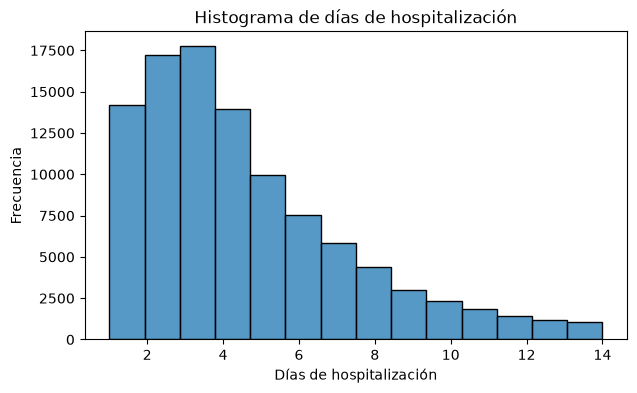

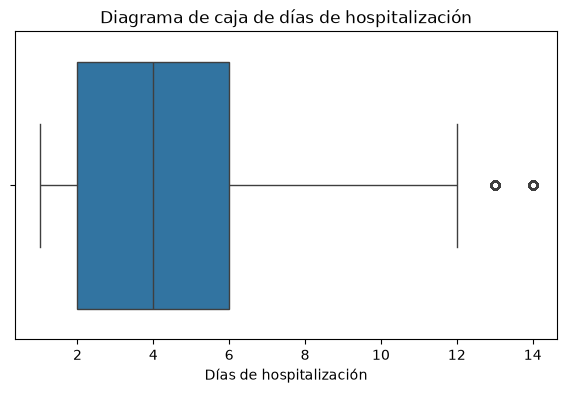

In [14]:
# Gráfico 1: Histograma de time_in_hospital
plt.figure(figsize=(7, 4))
sns.histplot(df_limpio["time_in_hospital"], bins=14)
plt.title("Histograma de días de hospitalización")
plt.xlabel("Días de hospitalización")
plt.ylabel("Frecuencia")
plt.show()

# Gráfico 2: Diagrama de caja de time_in_hospital
plt.figure(figsize=(7, 4))
sns.boxplot(x=df_limpio["time_in_hospital"])
plt.title("Diagrama de caja de días de hospitalización")
plt.xlabel("Días de hospitalización")
plt.show()

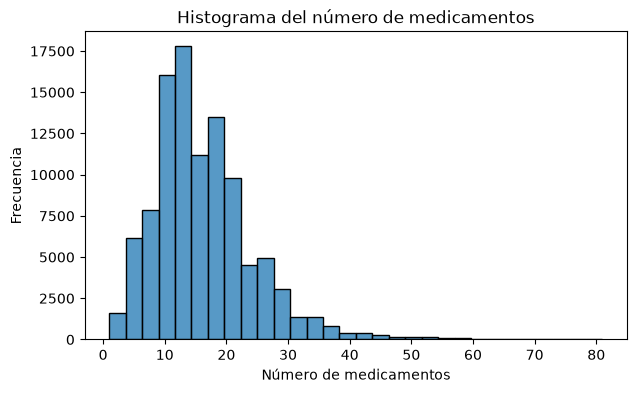

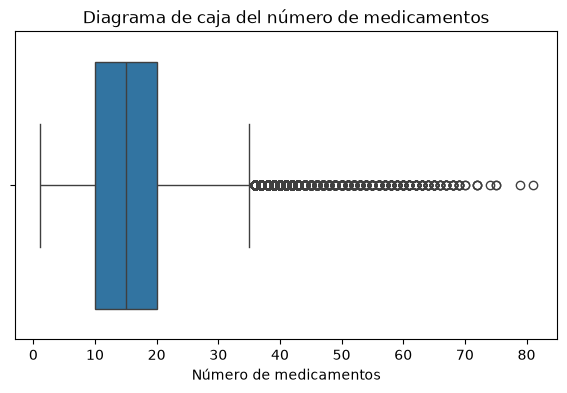

In [15]:
# Gráfico 3: Histograma de num_medications
plt.figure(figsize=(7, 4))
sns.histplot(df_limpio["num_medications"], bins=30)
plt.title("Histograma del número de medicamentos")
plt.xlabel("Número de medicamentos")
plt.ylabel("Frecuencia")
plt.show()

# Gráfico 4: Diagrama de caja de num_medications
plt.figure(figsize=(7, 4))
sns.boxplot(x=df_limpio["num_medications"])
plt.title("Diagrama de caja del número de medicamentos")
plt.xlabel("Número de medicamentos")
plt.show()

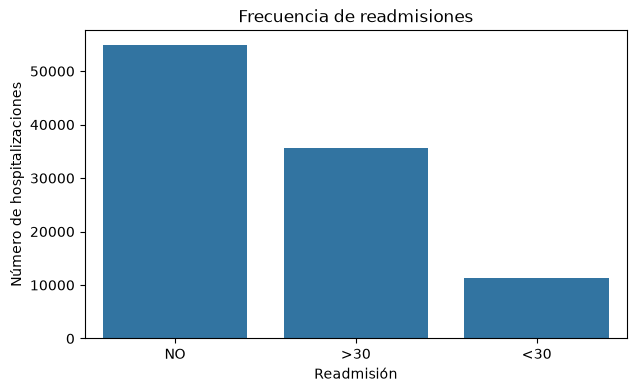

In [16]:
# Gráfico 5: Frecuencias de readmitted
plt.figure(figsize=(7, 4))
sns.countplot(data=df_limpio, x="readmitted", order=["NO", ">30", "<30"])
plt.title("Frecuencia de readmisiones")
plt.xlabel("Readmisión")
plt.ylabel("Número de hospitalizaciones")
plt.show()

In [17]:
# Outliers por IQR: time_in_hospital
q1_t = df_limpio["time_in_hospital"].quantile(0.25)
q3_t = df_limpio["time_in_hospital"].quantile(0.75)
iqr_t = q3_t - q1_t
inf_t = q1_t - 1.5 * iqr_t
sup_t = q3_t + 1.5 * iqr_t
mask_t = (df_limpio["time_in_hospital"] < inf_t) | (df_limpio["time_in_hospital"] > sup_t)

print("time_in_hospital")
print(f"Q1 = {q1_t}, Q3 = {q3_t}, IQR = {iqr_t}")
print(f"Límites: [{inf_t}, {sup_t}]")
print(f"Atípicos: {mask_t.sum()} ({mask_t.mean()*100:.2f}%)")

# Outliers por IQR: num_medications
q1_m = df_limpio["num_medications"].quantile(0.25)
q3_m = df_limpio["num_medications"].quantile(0.75)
iqr_m = q3_m - q1_m
inf_m = q1_m - 1.5 * iqr_m
sup_m = q3_m + 1.5 * iqr_m
mask_m = (df_limpio["num_medications"] < inf_m) | (df_limpio["num_medications"] > sup_m)

print("num_medications")
print(f"Q1 = {q1_m}, Q3 = {q3_m}, IQR = {iqr_m}")
print(f"Límites: [{inf_m}, {sup_m}]")
print(f"Atípicos: {mask_m.sum()} ({mask_m.mean()*100:.2f}%)")

time_in_hospital
Q1 = 2.0, Q3 = 6.0, IQR = 4.0
Límites: [-4.0, 12.0]
Atípicos: 2252 (2.21%)
num_medications
Q1 = 10.0, Q3 = 20.0, IQR = 10.0
Límites: [-5.0, 35.0]
Atípicos: 2557 (2.51%)


No eliminaria los valores atipicos ya que apesar de que si afecta en la normalización y estandarización son valores en los cuales la enfermedad puede estar mas grave por lo tanto se podria detectar de manera mas sencilla con esos valores.